In [1]:

from google.colab import files

files.download("/content/best_revenue_model.pkl")


FileNotFoundError: Cannot find file: /content/best_revenue_model.pkl

In [2]:

import os
import joblib
from google.colab import files

# Check that the trained model exists
if "best_model" in globals():
    model = best_model

elif "models" in globals() and "Random Forest" in models:
    model = models["Random Forest"]

else:
    print("Model not found. Please run the training cell first.")
    model = None

# Save and download the model
if model is not None:
    path = "/content/best_revenue_model.pkl"

    joblib.dump(model, path)

    print("Model saved:", os.path.exists(path))
    print("File size:", os.path.getsize(path), "bytes")

    files.download(path)


Model not found. Please run the training cell first.


In [3]:

print("Dataset available:", "df" in globals())



Dataset available: False


In [4]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()
filename = next(iter(uploaded))

if filename.lower().endswith(".csv"):
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_excel(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

Saving Team 6 - original data ,cleaned data.xlsx to Team 6 - original data ,cleaned data.xlsx
Dataset loaded successfully!
Dataset shape: (9864, 27)
Column names: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'Revenue']


In [5]:

import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from google.colab import files

# Separate features and target
X = df.drop(columns=["Revenue"])
y = df["Revenue"].astype(int)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create and train the model
model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Predict on test data
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Display evaluation metrics
print("MODEL TRAINED SUCCESSFULLY!")
print("-" * 35)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

# Save the trained model
path = "/content/best_revenue_model.pkl"
joblib.dump(model, path)

print("\nModel saved successfully!")
print("File exists:", os.path.exists(path))

# Download the saved model
files.download(path)


MODEL TRAINED SUCCESSFULLY!
-----------------------------------
Training samples: 7891
Testing samples: 1973
Accuracy: 0.8409
Precision: 0.6667
Recall: 0.0063
F1-score: 0.0126
ROC-AUC: 0.7267

Model saved successfully!
File exists: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Prepare data
X = df.drop(columns=["Revenue"])
y = df["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42, stratify=y
)

# Define three models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate
results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    prob = clf.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

comparison = pd.DataFrame(results).set_index("Model")
print(comparison.round(4))


                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                              
Logistic Regression    0.7182     0.2995  0.5714    0.3930   0.7223
Decision Tree          0.7506     0.2294  0.2381    0.2336   0.5431
Random Forest          0.8409     0.6667  0.0063    0.0126   0.7267


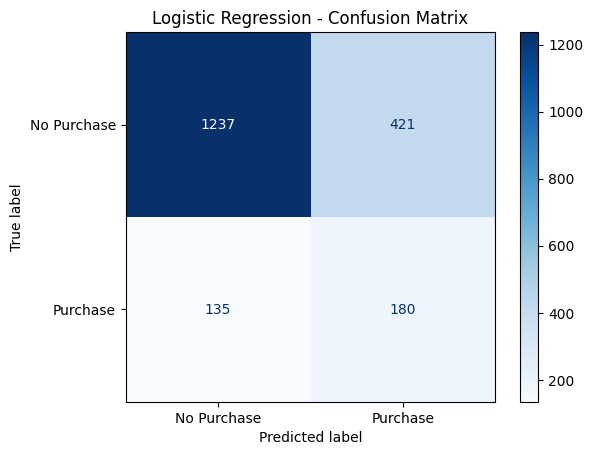

              precision    recall  f1-score   support

 No Purchase       0.90      0.75      0.82      1658
    Purchase       0.30      0.57      0.39       315

    accuracy                           0.72      1973
   macro avg       0.60      0.66      0.60      1973
weighted avg       0.81      0.72      0.75      1973


Top 10 influential features:
                Feature  Coefficient  Absolute Importance
ProductRelated_Duration     0.725483             0.725483
              Month_Nov     0.172785             0.172785
                Weekend     0.117234             0.117234
              Month_Dec     0.105858             0.105858
             PageValues     0.101736             0.101736
              Month_Mar     0.098079             0.098079
         ProductRelated     0.084019             0.084019
 Informational_Duration     0.072448             0.072448
              Month_Jul     0.070635             0.070635
          Informational    -0.068532             0.068532

Best

In [7]:

import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Select the model with the best F1-score
best_model = models["Logistic Regression"]

# Predictions
y_pred_best = best_model.predict(X_test)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best,
    display_labels=["No Purchase", "Purchase"],
    cmap="Blues"
)
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Classification report
print(classification_report(
    y_test, y_pred_best,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

# Feature importance from logistic regression coefficients
lr = best_model.named_steps["logisticregression"]

importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr.coef_[0],
    "Absolute Importance": abs(lr.coef_[0])
}).sort_values("Absolute Importance", ascending=False)

print("\nTop 10 influential features:")
print(importance.head(10).to_string(index=False))

# Save the selected model
joblib.dump(best_model, "/content/best_revenue_model.pkl")
print("\nBest model saved successfully!")


In [8]:

# Re-evaluate without PageValues
X_clean = df.drop(columns=["Revenue", "PageValues"])
y_clean = df["Revenue"].astype(int)

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean, y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

lr_clean = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

lr_clean.fit(X_train_clean, y_train_clean)

pred_clean = lr_clean.predict(X_test_clean)
prob_clean = lr_clean.predict_proba(X_test_clean)[:, 1]

print("Logistic Regression without PageValues")
print("Accuracy:", round(accuracy_score(y_test_clean, pred_clean), 4))
print("Precision:", round(precision_score(y_test_clean, pred_clean, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_clean, pred_clean, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test_clean, pred_clean, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_clean, prob_clean), 4))


Logistic Regression without PageValues
Accuracy: 0.7152
Precision: 0.2979
Recall: 0.5778
F1-score: 0.3931
ROC-AUC: 0.7241


In [9]:

import joblib
from google.colab import files

final_model = lr_clean

joblib.dump(final_model, "/content/final_revenue_model.pkl")

print("Final model saved successfully!")
print("Features used:", list(X_clean.columns))

files.download("/content/final_revenue_model.pkl")


Final model saved successfully!
Features used: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_Other', 'VisitorType_Returning_Visitor']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:

import os
import zipfile
import joblib
import pandas as pd

# Save model comparison results
comparison.to_csv("/content/model_comparison.csv")

# Save the final model
joblib.dump(final_model, "/content/final_revenue_model.pkl")

# Create a ZIP containing your project outputs
files_to_include = [
    "/content/final_revenue_model.pkl",
    "/content/model_comparison.csv",
    "/content/model_comparison.png",
    "/content/final_confusion_matrix.png",
    "/content/feature_importance.png"
]

with zipfile.ZipFile(
    "/content/ML_Assignment_Results.zip", "w"
) as zipf:
    for file_path in files_to_include:
        if os.path.exists(file_path):
            zipf.write(file_path, arcname=os.path.basename(file_path))
        else:
            print("Not found yet:", os.path.basename(file_path))

print("Project output ZIP created!")


Not found yet: model_comparison.png
Not found yet: final_confusion_matrix.png
Not found yet: feature_importance.png
Project output ZIP created!


In [11]:
from google.colab import files
files.download("/content/ML_Assignment_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from google.colab import files

uploaded = files.upload()

Saving final_revenue_model (1).pkl to final_revenue_model (1).pkl


In [13]:

import joblib

# Load the downloaded model
model = joblib.load("/content/final_revenue_model.pkl")

print("Model loaded successfully!")
print("Model type:", type(model))
print("Number of input features:", model.n_features_in_)


Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
Number of input features: 25


In [14]:

# Prepare test data without PageValues
X = df.drop(columns=["Revenue", "PageValues"])
y = df["Revenue"].astype(int)

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42,
    stratify=y
)

# Predict using the downloaded model
predictions = model.predict(X_test)

print("Actual values:", y_test.iloc[:10].tolist())
print("Predicted values:", predictions[:10].tolist())
print("Test accuracy:", round(accuracy_score(y_test, predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, predictions,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))


Actual values: [1, 0, 0, 0, 0, 0, 0, 0, 1, 0]
Predicted values: [1, 0, 0, 0, 1, 1, 0, 0, 1, 0]
Test accuracy: 0.7152

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.90      0.74      0.81      1658
    Purchase       0.30      0.58      0.39       315

    accuracy                           0.72      1973
   macro avg       0.60      0.66      0.60      1973
weighted avg       0.81      0.72      0.75      1973

